[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Tnecniv-Teikram/NSA-hyperspectral-course-2026/blob/main/31_from_notebook_to_product.ipynb)

*Running in Colab? Run the setup cell below first — it clones the course and installs what this notebook needs. Running locally? It does nothing.*

# 🚀 From notebook to product
### Space Academy 2026 · Hyperspectral course · Week 4 — Final project implementation and testing (Practical)

A notebook proves that a method *can* work. A **product** is what someone else can run, trust and act on
next month, when you are not in the room. This notebook turns the mangrove mapping of notebooks 15 and 21
into a small product and shows the four things that separate the two:

1. **A pipeline**: one function, one config, the same result every time.
2. **Outputs with provenance**: a Cloud-Optimised GeoTIFF, a metadata/QA file, a quicklook and a report.
3. **Tests**: automated checks that fail loudly when the code changes behaviour.
4. **Delivery**: a command-line tool and a small web app, so a user never has to open Jupyter.

**What you will learn**
- How to move analysis code out of a notebook into a module that the notebook, a CLI and an app all share
- What to write next to a result so it can be audited later (parameters, versions, quality flags)
- How to write fast, meaningful tests for geospatial code, and what to test
- How to profile a pipeline and find the step that actually costs time
- How to hand the result to a non-technical user

**Prerequisites:** `12_processing_workflow` (pipelines), `15_classification_classical` (the classifier),
`21_validation_accuracy_assessment` (how we know it works).

**Data:** `20250223_165546_32_4001` (Usulután, El Salvador — mangroves) and
`20250511_074311_00_4001` (Al Dhafra, UAE) for a second, harder run. `hu.get_scene()` finds the local
HDF5 or downloads it (~1 GB) from Planet's STAC catalogue.

In [ ]:
# --- Setup: works both in Google Colab and in a local environment --------------------
# In Colab this clones the course repository, installs the geospatial packages that Colab
# does not ship, and moves into the course folder so the notebook finds hsi_utils and data/.
# Locally it does nothing at all — your own environment is already active.
import os
import pathlib
import subprocess
import sys

REPO = "Tnecniv-Teikram/NSA-hyperspectral-course-2026"          # change with: python tools/set_repo_url.py <owner>/<repo>

if "google.colab" in sys.modules:
    course = pathlib.Path("/content/hyperspectral-course")
    if not course.exists():
        subprocess.run(["git", "clone", "--depth", "1", "-q",
                        f"https://github.com/{REPO}.git", str(course)], check=True)
    os.chdir(course)
    sys.path.insert(0, str(course))
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "h5py", "rasterio", "rioxarray", "xarray", "geopandas"], check=True)
    print("Colab ready — course at", course)
else:
    print("Local environment:", sys.executable.split("/")[-3])


In [1]:
# On Google Colab: upload hsi_utils.py and the app/ folder next to this notebook and uncomment:
# %pip install -q h5py numpy scipy matplotlib scikit-learn pandas rasterio requests joblib
import json
import subprocess
import sys
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

import hsi_utils as hu

sys.path.insert(0, str(Path.cwd() / "app"))      # the product module lives in app/
import mangrove_product as mp

plt.rcParams["figure.dpi"] = 90
SEED = 42
rng = np.random.default_rng(SEED)
OUT = hu.ensure_output_dir("31")
print("outputs →", OUT)

outputs → /home/course/hyperspectral_course_notebooks/outputs/31


## 1. The shape of a product

The analysis code lives in **`app/mangrove_product.py`**, not in this notebook. The notebook imports it,
exactly as the command line and the web app do:

```
app/mangrove_product.py     compute_features() · run_pipeline() · main()   ← the product
app/streamlit_app.py        a viewer for what run_pipeline() wrote         ← the delivery
tests/test_hsi_utils.py     automated checks                              ← the safety net
hsi_utils.py                shared I/O and spectral helpers               ← the library
```

Why not keep it all in the notebook? Because a notebook cannot be imported, scheduled, tested or
code-reviewed line by line, and cell execution order is invisible in the file. The rule of thumb:
**the notebook tells the story, the module does the work.**

Read the two key functions before running anything:

In [2]:
import inspect
print(inspect.getsource(mp.compute_features))
print(inspect.getsource(mp.minimum_mapping_unit))

def compute_features(scene, window, use_cloud_mask=True):
    """Return (features (6, rows, cols), valid mask) for one window of a scene."""
    b = {name: scene.read_band(nm, window, cloud=use_cloud_mask)
         for name, nm in dict(green=560, red=665, rededge=720, nir=860, swir1=1650, swir2=2200).items()}
    feats = np.stack([
        hu.nd(b["nir"], b["red"]),                                    # NDVI  — greenness
        hu.nd(b["green"], b["nir"]),                                  # NDWI  — open water
        hu.nd(b["nir"], b["swir1"]),                                  # NDMI  — canopy water
        hu.nd(b["nir"], b["rededge"]),                                # NDRE  — chlorophyll
        np.mean(np.stack([b["green"], b["red"], b["nir"]]), axis=0),  # brightness (NaN if any band is NaN)
        b["swir1"] / (b["swir2"] + 1e-6),                             # SWIR ratio — soil/leaf water
    ]).astype("float32")
    return feats, np.all(np.isfinite(feats), axis=0)

def minimum_

## 2. Train the model the product will use

The product maps one thing: **mangrove / not mangrove**. We train a small random forest on the six
named features of `compute_features()` (not the full 352 bands) for three reasons: it is fast enough to run
over a whole scene, the model file is small, and every input has a physical meaning we can explain to a user.

Labels come from ESA WorldCover 2021 (class 95 = mangroves), using only pure 30 m pixels, and the
train/test split is **spatially blocked** so neighbouring pixels cannot appear in both sets
(notebook 21 explains why this matters).

In [3]:
SCENE_ID = "20250223_165546_32_4001"
WINDOW = (100, 500, 100, 500)

scene = hu.get_scene(SCENE_ID)
feats, valid = mp.compute_features(scene, WINDOW)
labels, purity = hu.load_labels(SCENE_ID, WINDOW, min_purity=9)

y = np.where(labels == 95, 1, 0)                  # 1 = mangrove, 0 = anything else
usable = valid & (labels > 0)                     # only pixels WorldCover labels confidently

BLOCK = 50                                        # 50 px = 1.5 km blocks
H, W = usable.shape
blocks = (np.arange(H) // BLOCK)[:, None] * (W // BLOCK + 1) + (np.arange(W) // BLOCK)[None, :]
train_blocks = rng.permutation(blocks.max() + 1)[: int(0.6 * (blocks.max() + 1))]
is_train = np.isin(blocks, train_blocks)

Xtr, ytr = feats[:, usable & is_train].T, y[usable & is_train]
Xte, yte = feats[:, usable & ~is_train].T, y[usable & ~is_train]
print(f"train {len(ytr):,} px ({ytr.mean() * 100:.1f}% mangrove) | test {len(yte):,} px ({yte.mean() * 100:.1f}% mangrove)")

train 84,288 px (45.6% mangrove) | test 56,828 px (33.5% mangrove)


In [4]:
import joblib
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

model = RandomForestClassifier(n_estimators=150, min_samples_leaf=25, class_weight="balanced",
                               n_jobs=4, random_state=SEED).fit(Xtr, ytr)
pred = model.predict(Xte)
print(confusion_matrix(yte, pred))
print(classification_report(yte, pred, target_names=["other", "mangrove"], digits=3))

joblib.dump(model, mp.MODEL_PATH)
print(f"model saved: {mp.MODEL_PATH.name} ({mp.MODEL_PATH.stat().st_size / 1e3:.0f} kB)")
print("feature importances:",
      {n: round(float(v), 3) for n, v in zip(mp.FEATURE_NAMES, model.feature_importances_)})

[[37480   319]
 [  614 18415]]
              precision    recall  f1-score   support

       other      0.984     0.992     0.988     37799
    mangrove      0.983     0.968     0.975     19029

    accuracy                          0.984     56828
   macro avg      0.983     0.980     0.981     56828
weighted avg      0.984     0.984     0.984     56828

model saved: mangrove_rf.joblib (5785 kB)
feature importances: {'NDVI': 0.164, 'NDWI': 0.087, 'NDMI': 0.113, 'NDRE': 0.133, 'brightness': 0.252, 'swir_ratio': 0.251}


### Choosing the threshold *before* shipping

`run_pipeline` turns a probability into a yes/no map at a threshold. That single number is a product
decision, not a technical detail: a low threshold over-reports mangrove (annoying false alarms), a high one
misses degraded edges. Look at the trade-off and write down why you chose what you chose.

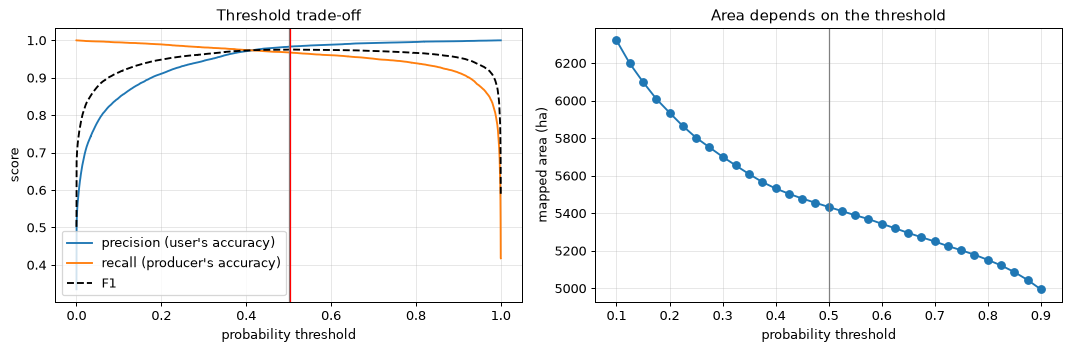

best F1 0.975 at threshold 0.50; the product ships 0.50 (F1 0.975) because it is easier to explain and re-use.


In [5]:
from sklearn.metrics import precision_recall_curve

prob_te = model.predict_proba(Xte)[:, 1]
precision, recall, thr = precision_recall_curve(yte, prob_te)
f1 = 2 * precision * recall / (precision + recall + 1e-9)
best = int(np.argmax(f1[:-1]))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(thr, precision[:-1], label="precision (user's accuracy)")
ax[0].plot(thr, recall[:-1], label="recall (producer's accuracy)")
ax[0].plot(thr, f1[:-1], "k--", label="F1")
ax[0].axvline(0.5, color="grey", lw=1); ax[0].axvline(thr[best], color="red", lw=1)
ax[0].set(xlabel="probability threshold", ylabel="score", title="Threshold trade-off")
ax[0].legend(); ax[0].grid(alpha=.3)

px_ha = scene.res_x * scene.res_y / 1e4
full_prob = np.full(valid.shape, np.nan, dtype="float32")
full_prob[valid] = model.predict_proba(feats[:, valid].T)[:, 1]
ths = np.linspace(0.1, 0.9, 33)
ax[1].plot(ths, [(np.nan_to_num(full_prob) >= t).sum() * px_ha for t in ths], "o-")
ax[1].axvline(0.5, color="grey", lw=1)
ax[1].set(xlabel="probability threshold", ylabel="mapped area (ha)", title="Area depends on the threshold")
ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

print(f"best F1 {f1[best]:.3f} at threshold {thr[best]:.2f}; the product ships 0.50 "
      f"(F1 {f1[np.searchsorted(thr, 0.5)]:.3f}) because it is easier to explain and re-use.")

## 3. Run the pipeline

One call produces everything a user receives. Note what `run_pipeline` writes next to the data:
**metadata.json** (parameters, software versions, bounding box, attribution) and **quality flags** — the
run tells you itself when not to trust it.

In [6]:
meta = mp.run_pipeline(SCENE_ID, WINDOW)
print(json.dumps({k: meta[k] for k in ("run_id", "results", "quality_flags", "runtime_seconds")}, indent=2))

20250223_165546_32_4001_20260920T171502Z: 5,386 ha mangrove, 100.0% usable pixels, 0.7 s → /home/course/hyperspectral_course_notebooks/outputs/31/20250223_165546_32_4001_20260920T171502Z
{
  "run_id": "20250223_165546_32_4001_20260920T171502Z",
  "results": {
    "mangrove_area_ha": 5385.8,
    "mangrove_pixels": 59842,
    "valid_pixel_fraction": 1.0,
    "mean_probability_in_mangrove": 0.975
  },
  "quality_flags": [
    "OK"
  ],
  "runtime_seconds": 0.7
}


['mangrove.tif', 'metadata.json', 'quicklook.png', 'report.html']


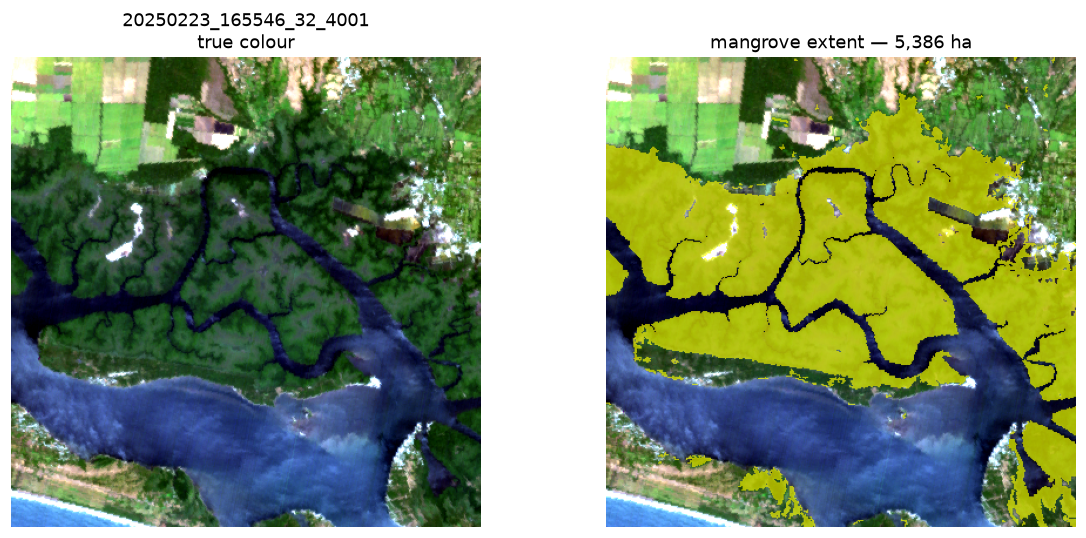

In [7]:
run_dir = Path(hu.OUTPUT_DIR / "31" / meta["run_id"])
print(sorted(p.name for p in run_dir.iterdir()))
from IPython.display import Image, display
display(Image(filename=str(run_dir / "quicklook.png"), width=900))

### The same product, a different place

A product must behave sensibly on input it was not tuned for. Running the El Salvador model over the UAE
coast (a different mangrove species, *Avicennia marina*, on a bright sabkha background) is the domain-shift
test of notebook 20, in production form. Watch the quality flags and be honest about the result.

20250511_074311_00_4001_20260920T171502Z: 0 ha mangrove, 60.6% usable pixels, 0.6 s → /home/course/hyperspectral_course_notebooks/outputs/31/20250511_074311_00_4001_20260920T171502Z


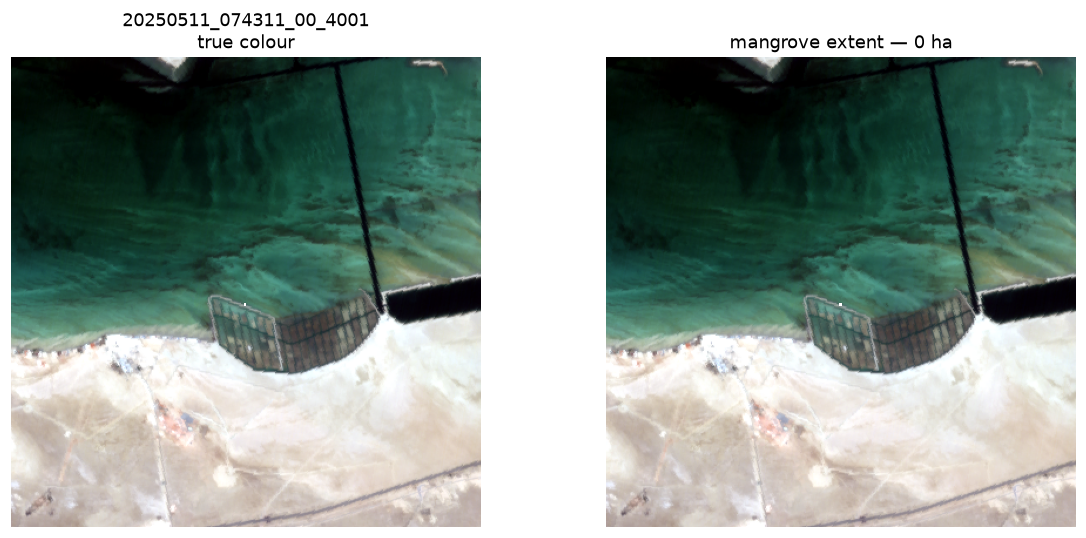

flags: ['NO_DETECTION: no mangrove pixels found']
area: 0 ha


In [8]:
meta_uae = mp.run_pipeline("20250511_074311_00_4001", (250, 650, 350, 750))
display(Image(filename=str(hu.OUTPUT_DIR / "31" / meta_uae["run_id"] / "quicklook.png"), width=900))
print("flags:", meta_uae["quality_flags"])
print(f"area: {meta_uae['results']['mangrove_area_ha']:,.0f} ha")

**What actually happened:** the run reports **0 ha** and raises `NO_DETECTION`. Two things to take from that:

- The model did **not** invent mangroves on bright sabkha, dark shallow water or irrigated desert planting —
  the failure mode you most fear when a model meets a landscape it has never seen. ESA WorldCover also maps no
  mangrove in this scene, so "nothing here" is the defensible answer for *this window*.
- But absence of a detection is not evidence of absence. The UAE does have large *Avicennia marina* stands
  (around Abu Dhabi island and Eastern Mangroves), just not inside this window. A product that returns 0 ha must
  therefore say **where it looked**, which is exactly what `bbox_lonlat` and the quality flags in `metadata.json` do.

The honest sentence for a report is: *"the El Salvador model found no mangrove in this Al Dhafra window and did
not produce false positives on sabkha; it has not been validated on Gulf mangroves."*

## 4. Testing: how you know you did not break it

Two kinds of tests earn their place in a project like this:

| Kind | Question it answers | Example |
|------|--------------------|---------|
| **Unit tests** | does this function still do what it promises? | `hu.nd(3, 1) == 0.5`; a subset round-trips to the same values and grid |
| **Product smoke tests** | does a whole run still produce something sane? | outputs exist, CRS is set, area is in a plausible range, no all-NaN layer |

`tests/test_hsi_utils.py` holds the unit tests. They are fast (no downloads) and the ones that need a scene
skip themselves when no HDF5 is around, so they also run in CI.

In [9]:
r = subprocess.run([sys.executable, "-m", "pytest", "tests/", "-q"], capture_output=True, text=True)
print(r.stdout[-1500:] or r.stderr[-1500:])

.......................                                                  [100%]
23 passed in 0.31s



Now a **smoke test for the product itself**. These assertions encode what must be true of *any* run;
if a future change breaks one, you find out immediately instead of in a presentation.

In [10]:
import rasterio


def smoke_test(meta):
    """Assert the invariants every product run must satisfy."""
    run = hu.OUTPUT_DIR / "31" / meta["run_id"]
    for name in ("mangrove.tif", "metadata.json", "quicklook.png", "report.html"):
        assert (run / name).exists(), f"missing output: {name}"

    with rasterio.open(run / "mangrove.tif") as src:
        assert src.crs is not None and src.transform.a > 0, "product must be georeferenced"
        assert src.count == 2 and src.descriptions[0] == "mangrove_mask"
        mask, prob = src.read(1), src.read(2)
    assert set(np.unique(mask)) <= {0, 1}, "mask must be binary"
    assert 0 <= prob.max() <= 100, "probability must be stored as 0–100 %"
    assert np.isfinite(mask).all(), "mask must not contain NaN"

    area = meta["results"]["mangrove_area_ha"]
    scene_area = mask.size * (meta["pixel_size_m"] ** 2) / 1e4
    assert 0 <= area <= scene_area, "area outside the window area"
    assert meta["results"]["valid_pixel_fraction"] <= 1.0
    assert meta["attribution"].startswith("Tanager"), "attribution missing"
    return f"✅ {meta['run_id']}: {area:,.0f} ha of {scene_area:,.0f} ha window"


for m in (meta, meta_uae):
    print(smoke_test(m))

✅ 20250223_165546_32_4001_20260920T171502Z: 5,386 ha of 14,400 ha window
✅ 20250511_074311_00_4001_20260920T171502Z: 0 ha of 14,400 ha window


**What to test in your own project** (and what not to):

- ✅ Pure functions with known answers: indices, band picking, unit conversions, geometry.
- ✅ Round-trips: write then read a GeoTIFF/subset and compare.
- ✅ Invariants: shapes, ranges (reflectance ≤ ~1.5), CRS present, no silent all-NaN output.
- ✅ Regression on a tiny fixture: one small window, a stored expected area (±tolerance).
- ❌ Do not test exact floating-point equality of model accuracies, or anything that needs a 1 GB download
  in CI. Mark those `@pytest.mark.slow` or skip them without local data, as `tests/` does.

## 5. Delivery 1 — the command line

The same module has a CLI, so the product can run on a server, in a cron job, or from a colleague's terminal:

```bash
python app/mangrove_product.py --scene 20250223_165546_32_4001 --window 100 500 100 500
```

In [11]:
r = subprocess.run([sys.executable, "app/mangrove_product.py", "--scene", SCENE_ID,
                    "--window", "150", "400", "150", "400"], capture_output=True, text=True)
print(r.stdout[-800:] or r.stderr[-800:])

20250223_165546_32_4001_20260920T171505Z: 3,503 ha mangrove, 100.0% usable pixels, 1.6 s → /home/course/hyperspectral_course_notebooks/outputs/31/20250223_165546_32_4001_20260920T171505Z
{
  "mangrove_area_ha": 3502.7,
  "mangrove_pixels": 38919,
  "valid_pixel_fraction": 1.0,
  "mean_probability_in_mangrove": 0.979
}



**Scheduling it** is then a one-liner. A monthly run, logging to a file:

```cron
0 3 1 * *  cd /srv/mangrove && /srv/mangrove/.venv/bin/python app/mangrove_product.py \
           --scene $(python tools/latest_scene.py) >> logs/run.log 2>&1
```

For the PoC you do not need the cron job — you need to show that your code *could* be scheduled:
no manual steps, no interactive input, exit code and log output that a machine can check.

## 6. Delivery 2 — a small web app

`app/streamlit_app.py` reads the runs in `outputs/31/` and gives a non-technical user the map, the
area, the quality flags, a pixel inspector and a download button. Start it from the course folder:

```bash
streamlit run app/streamlit_app.py
```

In [12]:
# Check that the app at least imports and that Streamlit is installed
r = subprocess.run([sys.executable, "-c",
                    "import streamlit, ast, pathlib; "
                    "ast.parse(pathlib.Path('app/streamlit_app.py').read_text()); "
                    "print('streamlit', streamlit.__version__, '· app parses OK')"],
                   capture_output=True, text=True)
print(r.stdout.strip() or "Streamlit not installed — pip install streamlit (the app is optional)")
print("\nRuns the app will show:")
for d in sorted((hu.OUTPUT_DIR / "31").glob("*/")):
    if (d / "metadata.json").exists():
        m = json.loads((d / "metadata.json").read_text())
        print(f"  {d.name}  {m['results']['mangrove_area_ha']:>8,.0f} ha  flags={m['quality_flags']}")

streamlit 1.64.0 · app parses OK

Runs the app will show:
  20250223_165546_32_4001_20260920T171502Z     5,386 ha  flags=['OK']
  20250223_165546_32_4001_20260920T171505Z     3,503 ha  flags=['OK']
  20250511_074311_00_4001_20260920T171502Z         0 ha  flags=['NO_DETECTION: no mangrove pixels found']


### Other delivery routes

| Route | When it fits | Effort |
|-------|--------------|--------|
| **Static outputs** (COG + report) on a shared drive or S3 | The user has GIS software already | lowest |
| **Streamlit / Dash app** | Non-technical users need to look and filter | low |
| **Web map** (COG + `leafmap`/Leaflet, tiles from a titiler service) | Results must sit on top of other layers | medium |
| **REST API** | Another system consumes the result | medium |
| **Alerting** (email/SMS when a threshold is crossed) | The user only cares about change | medium |

A minimal API is about fifteen lines, and the pipeline function is already the hard part:

```python
from fastapi import FastAPI
import mangrove_product as mp

app = FastAPI()

@app.post("/mangrove")
def mangrove(scene_id: str, r0: int, r1: int, c0: int, c1: int):
    meta = mp.run_pipeline(scene_id, (r0, r1, c0, c1))
    return {"area_ha": meta["results"]["mangrove_area_ha"], "flags": meta["quality_flags"],
            "run_id": meta["run_id"]}
```

(Run it with `uvicorn api:app`. For real use add authentication, a job queue for long runs, and rate limits.)

## 7. Profiling: where does the time actually go?

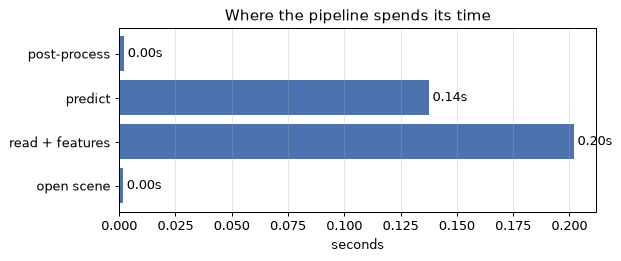


   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
      3/2    0.000    0.000    0.199    0.100 /tmp/course/venv/lib/python3.13/site-packages/IPython/core/interactiveshell.py:3786(run_code)
        2    0.000    0.000    0.199    0.100 {built-in method builtins.exec}
        6    0.001    0.000    0.196    0.033 /home/course/hyperspectral_course_notebooks/hsi_utils.py:408(read_band)
       24    0.192    0.008    0.192    0.008 /tmp/course/venv/lib/python3.13/site-packages/h5py/_hl/dataset.py:853(__getitem__)
        1    0.000    0.000    0.132    0.132 /home/course/hyperspectral_course_notebooks/app/mangrove_product.py:33(compute_features)
        3    0.000    0.000    0.067    0.022 /opt/miniconda3/lib/python3.13/asyncio/base_events.py:1981(_run_once)
        6    0.000    0.000    0.006    0.001 /home/course/hyperspectral_course_notebooks/hsi_utils.py:385(valid_mask)
        6    0.000    0.000    0.006    0.001 /home/course/hyperspectral_course_notebooks/hs

In [13]:
import cProfile
import pstats
import io

stages = {}
t = time.time(); scene2 = hu.get_scene(SCENE_ID); stages["open scene"] = time.time() - t
t = time.time(); f2, v2 = mp.compute_features(scene2, WINDOW); stages["read + features"] = time.time() - t
t = time.time()
prob_map = np.full(v2.shape, np.nan, dtype="float32")
prob_map[v2] = model.predict_proba(f2[:, v2].T)[:, 1]
stages["predict"] = time.time() - t
t = time.time(); _ = mp.minimum_mapping_unit(np.nan_to_num(prob_map) >= 0.5, 5); stages["post-process"] = time.time() - t

fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(list(stages), list(stages.values()), color="#4C72B0")
ax.set(xlabel="seconds", title="Where the pipeline spends its time")
for i, v in enumerate(stages.values()):
    ax.text(v, i, f" {v:.2f}s", va="center")
ax.grid(axis="x", alpha=.3); plt.tight_layout(); plt.show()

pr = cProfile.Profile(); pr.enable()
mp.compute_features(scene2, WINDOW)
pr.disable()
s = io.StringIO(); pstats.Stats(pr, stream=s).sort_stats("cumulative").print_stats(8)
print("\n".join(s.getvalue().splitlines()[4:14]))

**Reading this:** almost all the time is I/O — decompressing HDF5 chunks — not maths. That tells you where
optimisation pays:

1. **Read once, reuse.** Read the bands you need in a single pass instead of calling `read_band` repeatedly
   (each call re-reads and re-decompresses).
2. **Read less.** A window or a stride beats the full scene; `tools/make_subsets.py` makes a 30 MB subset.
3. **Tile** for full scenes (notebook 30) so memory stays bounded.
4. Only then think about the model. A random forest on six features is already milliseconds per 10⁵ pixels.

## 8. Handover checklist

Before you call it finished, check that someone else can take it over:

- [ ] `pip install -r requirements.txt` then one documented command reproduces the outputs
- [ ] No absolute paths, no manual steps, no cells that must be run out of order
- [ ] Every output has metadata: parameters, versions, scene IDs, date, attribution
- [ ] Quality flags tell the user when a result is not trustworthy
- [ ] Tests pass, and it is obvious how to run them (`pytest tests/ -q`)
- [ ] A user-facing view exists (app, report or API) and someone outside the team has tried it
- [ ] `templates/submission_checklist.md` is fully ticked

## ✏️ Your turn

1. ⭐ **Change the threshold** to the best-F1 value found in section 2 and rerun the pipeline
   (`mp.run_pipeline(..., )` after editing `MODEL["threshold"]`, or pass a new `min_pixels`).
   How much does the mapped area change? Which number would you give a ministry, and with what caveat?
2. ⭐⭐ **Add a quality flag** to `_quality_flags()` in `app/mangrove_product.py`: warn when more than 20 %
   of the mangrove pixels sit within one pixel of the window edge (the true extent is probably cut off).
   Add a test for it in `tests/`.
3. ⭐⭐ **Write a regression test** that runs the pipeline on a small fixed window and asserts the area is
   within ±5 % of today's value. Then change `min_pixels` and watch it fail — that is the point.
4. ⭐⭐⭐ **Make it a change product**: extend `run_pipeline` to accept two scene IDs and report *gain and
   loss* in hectares between them (notebook 30 has the co-registration you need), with a flag when the two
   dates have very different sun angles.
5. ⭐⭐⭐ **Swap in your own project**: copy `app/mangrove_product.py` to `app/<your_product>.py` and replace
   the feature and model sections with your method, keeping the metadata, flags, tests and CLI.

<details><summary>Hint for 2</summary>

```python
edge = np.zeros_like(mangrove); edge[0, :] = edge[-1, :] = edge[:, 0] = edge[:, -1] = True
from scipy import ndimage
near_edge = ndimage.binary_dilation(edge) & mangrove
if mangrove.sum() and near_edge.sum() / mangrove.sum() > 0.2:
    flags.append("EDGE_TRUNCATED: >20% of detections touch the window edge")
```
(You will need to pass `mangrove` into `_quality_flags`.)
</details>

## Key takeaways

- The notebook tells the story; an importable **module** does the work, so the CLI, the app and the tests
  all run the *same* code.
- Ship **provenance and quality flags** with every result. A number without parameters and a date cannot be audited.
- **Tests** are cheap for pure functions and round-trips, and they are what lets you change code confidently.
- A product decision like the **threshold** belongs in the metadata and in your presentation, not hidden in a cell.
- Most of the runtime is **I/O**: read once, read less, tile for big scenes.

---
> 📖 Data: Tanager — CC-BY-4.0 © Planet Labs PBC · labels: ESA WorldCover 2021 v200 — CC-BY 4.0